In [21]:
# ML-5: Random Forest to Predict Safety of the Car

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [22]:
# 1. Download Dataset
import kagglehub
path = kagglehub.dataset_download("elikplim/car-evaluation-data-set")

Using Colab cache for faster access to the 'car-evaluation-data-set' dataset.


In [28]:
# 2. Load Dataset (Without Headers)
import os
csv_path = os.path.join(path, "car_evaluation.csv")

In [29]:
df = pd.read_csv(csv_path, header=None)

In [30]:
df.columns = [
    'buying', 'maint', 'doors','persons', 'lug_boot', 'safety', 'class'
]

In [31]:
# 3. Explore Dataset
print("First 5 Rows:")
print(df.head())

First 5 Rows:
  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc


In [32]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1728, 7)


In [33]:
print("Columns:", df.columns.tolist())

Columns: ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']


In [34]:
# 4. Check Missing Values
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64


In [35]:
# 5. Encode Categorical Data
encoder = LabelEncoder()

for col in df.columns:
    df[col] = encoder.fit_transform(df[col])

In [36]:
print("Encoded Dataset:")
print(df.head(10))

Encoded Dataset:
   buying  maint  doors  persons  lug_boot  safety  class
0       3      3      0        0         2       1      2
1       3      3      0        0         2       2      2
2       3      3      0        0         2       0      2
3       3      3      0        0         1       1      2
4       3      3      0        0         1       2      2
5       3      3      0        0         1       0      2
6       3      3      0        0         0       1      2
7       3      3      0        0         0       2      2
8       3      3      0        0         0       0      2
9       3      3      0        1         2       1      2


In [37]:
# 6. Split Features and Target
X = df.drop('class', axis=1)
y = df['class']

In [38]:
# 7. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [39]:
# 8. Create Random Forest Model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [41]:
# 9. Train Model
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [42]:
# 10. Predictions
y_pred = model.predict(X_test)

In [44]:
# 11. Model Evaluation
print("Accuracy Score:", accuracy_score(y_test, y_pred))

Accuracy Score: 0.9826589595375722


In [45]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.95      0.96        77
           1       0.93      0.93      0.93        14
           2       0.99      1.00      0.99       242
           3       1.00      0.92      0.96        13

    accuracy                           0.98       346
   macro avg       0.97      0.95      0.96       346
weighted avg       0.98      0.98      0.98       346



In [46]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Confusion Matrix:
[[ 73   1   3   0]
 [  1  13   0   0]
 [  0   0 242   0]
 [  1   0   0  12]]


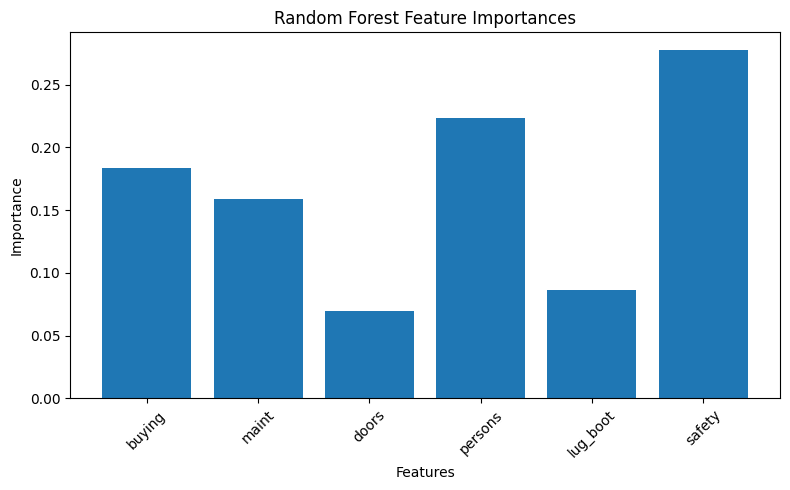

In [47]:
# 12. Feature Importance Graph
plt.figure(figsize=(8, 5))

plt.bar(X.columns, model.feature_importances_)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importances")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()